# 04 · A template from the data: TIRAVEL

**What you'll learn**

- how TIRAVEL builds a template out of the observations themselves
- the alignment measure ρ: why it peaks at the right velocities, and why noise keeps it below 1
- why only velocity *differences* matter to TIRAVEL
- on simulated, noisy data: the TIRAVEL template is far less noisy than any single epoch, matches
  the true spectrum and gives RVs consistent with the truth within their errors
- on HARPS spectra of TOI-193: it reproduces a PHOENIX library template

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import TIRAVEL, Observations, Template, instruments
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates
from sparta.plotting import (EXTRA_COLOR, apply_style, plot_curve, plot_data, plot_extra,
                             plot_model, plot_points)

apply_style()

def standardise(x):
    """Zero mean, unit variance: compares shapes regardless of scale."""
    return (x - x.mean()) / x.std()

def residual(x, truth):
    """x minus its best linear fit a + b * truth, divided by b: in units of the truth's flux."""
    design = np.column_stack([np.ones_like(truth), truth])
    (a, b), *_ = np.linalg.lstsq(design, x, rcond=None)
    return (x - a - b * truth) / b

## 1. The idea

UNICOR and TODCOR need a template. When no library model fits the star well (peculiar,
active or fast-rotating stars), TIRAVEL (Zucker & Mazeh 2006) builds one from the data:

1. take trial velocities $v_k$, one per epoch, and shift every spectrum back to rest;
2. resample them onto a common grid and normalise each (zero mean, unit norm);
3. form their $K \times K$ correlation matrix. If the velocities are right, all rows are the same
   spectrum plus noise, so its largest eigenvalue $\lambda_{\max}$ approaches $K$ (reaching it only
   without noise). The alignment measure is $\rho = (\lambda_{\max} - 1)/(K - 1)$, between 0 and 1;
4. co-add the epochs with the weights of the leading eigenvector: that is the template.

## 2. Simulated data: the truth is known

30 epochs of a single-lined star observed "like HARPS" (5000–5100 Å), with **photon noise at a
signal-to-noise of 50 per native pixel at the continuum**, typical of a real HARPS spectrum of a
bright star. The noise is drawn on the instrument's native pixels with a fixed seed.
`component_templates(sim)` is the noiseless spectrum the epochs were made from.

In [2]:
SNR = 50
rng = np.random.default_rng(5)
times = np.sort(rng.uniform(0, 30, 30))
rv_true = -8.0 + 25.0 * np.sin(2 * np.pi * times / 6.1)              # km/s
star = dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0)

def simulate(snr):
    """30 HARPS-like epochs of the star at signal-to-noise snr (None: noiseless)."""
    return Simulation(like="HARPS", windows_A=[(5000, 5100)], times=times, rv_kms=rv_true,
                      components=[star], snr=snr, noise="photon", seed=6)

sim = simulate(SNR)
obs = Observations(survey="SIMULATED", simulation=sim)
truth_template = component_templates(sim)[0]

obs.build_tiravel_template(rv_true)
tir = obs.tiravel
print(f"rho = {tir.rho:.4f}, effective number of contributing epochs = "
      f"{tir.diagnostics['n_eff']:.1f} of {obs.sample_size}")

rho = 0.9933, effective number of contributing epochs = 30.0 of 30


**Why ρ < 1: noise.** At the right velocities each normalised epoch is the common spectrum $s$
plus its own noise, so any two epochs correlate at about $\mathrm{var}(s)/(\mathrm{var}(s) + \sigma^2)$
and $\rho$ is that same number: $1 - \rho \approx \sigma^2/\mathrm{var}(s) \propto (S/N)^{-2}$.
So ρ measures the alignment *diluted by the noise*. Its absolute value says as much about the S/N
as about the velocities; what tells the velocities apart is that ρ is *largest* at the right ones.
Check against the noise-only prediction (photon noise: $\sigma^2 = \langle s \rangle / (S/N)^2$) and
a noiseless twin of the same data:

In [3]:
grid = tir.grids[0]
truth_on_grid = np.interp(grid, truth_template.model.wv[0], truth_template.model.sp[0])
predicted = 1 / (1 + truth_on_grid.mean() / SNR**2 / truth_on_grid.var())
noiseless = Observations(survey="SIMULATED", simulation=simulate(None))
rho_noiseless = TIRAVEL().build_template(noiseless.spec_list, rv_true).rho

print(f"rho measured at S/N {SNR}:          {tir.rho:.4f}")
print(f"rho predicted from the noise alone: {predicted:.4f}")
print(f"rho of the noiseless twin:          {rho_noiseless:.6f}")

rho measured at S/N 50:          0.9933
rho predicted from the noise alone: 0.9924
rho of the noiseless twin:          1.000000


The noise accounts for essentially all of 1 − ρ. The measured ρ is slightly above the prediction
because resampling the shifted epochs onto the common grid smooths their noise a little.

**ρ still peaks at the true velocities.** Scale the velocity curve by a factor *s*: *s* = 0
assumes the star is not moving, *s* = 1 is the truth. With noise the whole curve sits below 1,
but its maximum stays at *s* = 1, which is what would let an optimiser find the velocities.

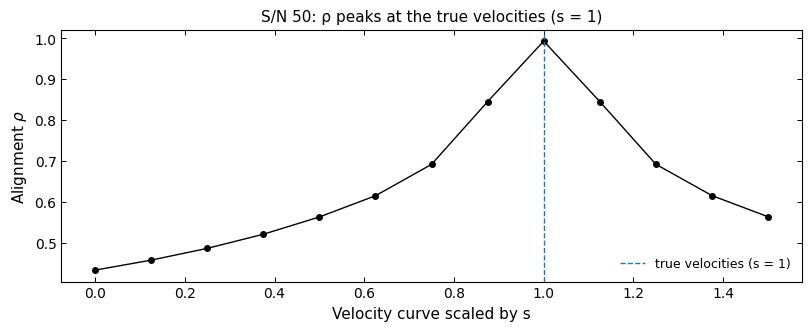

rho at s = 0: 0.434;  at s = 1: 0.9933;  maximum at s = 1.000


In [4]:
scales = np.linspace(0, 1.5, 13)
rhos = [TIRAVEL().build_template(obs.spec_list, s * rv_true).rho for s in scales]

fig, ax = plt.subplots()
plot_curve(ax, scales, rhos, marker="o", ms=4)
ax.axvline(1.0, color=EXTRA_COLOR, ls="--", lw=1, label="true velocities (s = 1)")
ax.set_xlabel("Velocity curve scaled by s")
ax.set_ylabel(r"Alignment $\rho$")
ax.set_title(f"S/N {SNR}: ρ peaks at the true velocities (s = 1)")
ax.legend(loc="lower right")
plt.show()
print(f"rho at s = 0: {rhos[0]:.3f};  at s = 1: {rhos[np.argmin(np.abs(scales - 1))]:.4f};  "
      f"maximum at s = {scales[np.argmax(rhos)]:.3f}")

**Only differences matter.** Adding the same constant to every velocity aligns the spectra just
as well, but the template's rest frame moves with it; RVs measured against that template move
by the same constant.

In [5]:
offset = TIRAVEL().build_template(obs.spec_list, rv_true + 5.0)
print(f"rho with the true velocities:      {tir.rho:.6f}")
print(f"rho with every velocity + 5 km/s:  {offset.rho:.6f}")

obs.calc_rv_against_template(offset.template, dv=0.1, vel_bound=40)
print(f"RVs against the offset template minus the truth: {np.mean(obs.vels - rv_true):+.3f} km/s on average")

rho with the true velocities:      0.993292
rho with every velocity + 5 km/s:  0.993292


RVs against the offset template minus the truth: +5.000 km/s on average


**Is the template less noisy than the data?** TIRAVEL's template is a weighted sum of
normalised spectra, so we compare shapes: subtract the best linear fit of the noiseless truth
from one aligned epoch and from the template. Averaging $K$ epochs with near-equal weights
should cut the noise by $\sqrt{n_\mathrm{eff}}$.

rms about the truth (continuum units): one epoch 0.0168 (median), template 0.0031
noise reduction 5.38, sqrt(n_eff) = 5.48
correlation with the truth: one epoch 0.9966, template 0.99989


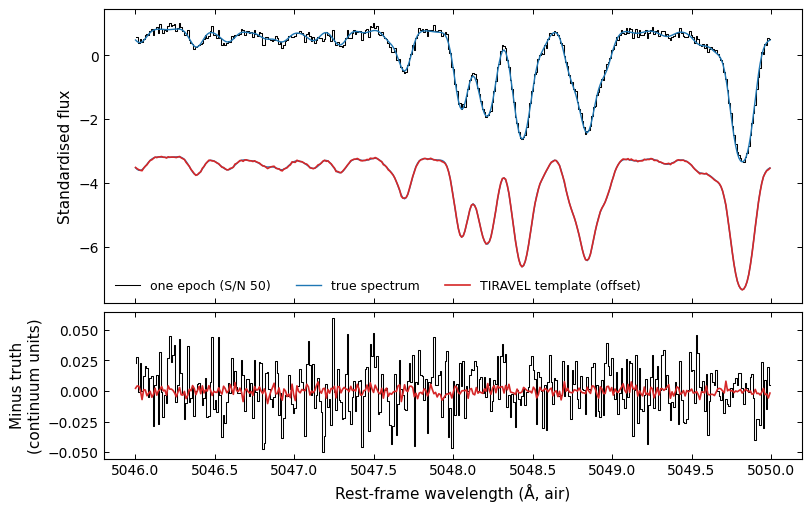

In [6]:
template_flux = tir.template.model.sp[0]
epoch = tir.aligned[0][1]                     # epoch 1, shifted to rest and resampled
noise_epochs = np.median([residual(row, truth_on_grid).std() for row in tir.aligned[0]])
noise_template = residual(template_flux, truth_on_grid).std()
print(f"rms about the truth (continuum units): one epoch {noise_epochs:.4f} (median), "
      f"template {noise_template:.4f}")
print(f"noise reduction {noise_epochs / noise_template:.2f}, "
      f"sqrt(n_eff) = {np.sqrt(tir.diagnostics['n_eff']):.2f}")
print(f"correlation with the truth: one epoch {np.corrcoef(epoch, truth_on_grid)[0, 1]:.4f}, "
      f"template {np.corrcoef(template_flux, truth_on_grid)[0, 1]:.5f}")

zoom = (grid > 5046) & (grid < 5050)
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(8, 5), height_ratios=[2, 1])
plot_data(top, grid[zoom], standardise(epoch)[zoom], label="one epoch (S/N 50)")
plot_extra(top, grid[zoom], standardise(truth_on_grid)[zoom], label="true spectrum")
plot_extra(top, grid[zoom], standardise(truth_on_grid)[zoom] - 4)
plot_model(top, grid[zoom], standardise(template_flux)[zoom] - 4, label="TIRAVEL template (offset)")
top.set_ylabel("Standardised flux")
top.legend(loc="lower left", ncols=3)
plot_data(bottom, grid[zoom], residual(epoch, truth_on_grid)[zoom])
plot_model(bottom, grid[zoom], residual(template_flux, truth_on_grid)[zoom])
bottom.set_xlabel("Rest-frame wavelength (Å, air)")
bottom.set_ylabel("Minus truth\n(continuum units)")
plt.show()

**And the RVs?** Measured against the TIRAVEL template and against the noiseless true one. If the
uncertainties are right, the rms about the true velocities should match the median uncertainty.

In [7]:
for name, template in [("true template", truth_template), ("TIRAVEL template", tir.template)]:
    obs.calc_rv_against_template(template, dv=0.1, vel_bound=40)
    rms, median_err = np.std(obs.vels - rv_true), np.median(obs.evels)
    print(f"{name:16s}: rms about the truth {rms * 1e3:.1f} m/s, "
          f"median uncertainty {median_err * 1e3:.1f} m/s, ratio {rms / median_err:.2f}")

true template   : rms about the truth 3.1 m/s, median uncertainty 3.6 m/s, ratio 0.86


TIRAVEL template: rms about the truth 3.5 m/s, median uncertainty 3.6 m/s, ratio 0.98


Both agree with the truth within their errors. The TIRAVEL template carries the co-added noise of
the 30 epochs, about $1/\sqrt{30}$ of one epoch's, so it costs little precision against a perfect
noiseless template.

**How S/N sets ρ and the template.** The same star at three signal-to-noise ratios: $1 - \rho$
scales as $(S/N)^{-2}$, and the template's noise as $(S/N)^{-1}$, always about $\sqrt{30}$ below a
single epoch's. (One seed for all three: the same noise pattern, scaled, which is why the
ratio repeats exactly.)

In [8]:
print(" S/N    rho    (1-rho)(S/N)^2   noise: one epoch   template   ratio")
for snr in (25, 50, 100):
    sweep_obs = Observations(survey="SIMULATED", simulation=simulate(snr))
    built = TIRAVEL().build_template(sweep_obs.spec_list, rv_true)
    one = np.median([residual(row, truth_on_grid).std() for row in built.aligned[0]])
    coadded = residual(built.template.model.sp[0], truth_on_grid).std()
    print(f"{snr:4d}  {built.rho:.4f}  {(1 - built.rho) * snr**2:10.1f}  "
          f"{one:16.4f}  {coadded:9.4f}  {one / coadded:6.2f}")

 S/N    rho    (1-rho)(S/N)^2   noise: one epoch   template   ratio
  25  0.9737        16.4            0.0336     0.0062    5.38


  50  0.9933        16.8            0.0168     0.0031    5.38
 100  0.9983        16.9            0.0084     0.0016    5.38


## 3. Real data: HARPS spectra of TOI-193

TOI-193 (LTT 9779) is a quiet, slowly rotating Sun-like star, for which a PHOENIX model is a good
template. So this is a validation: TIRAVEL should rebuild a template like the library one, from
the data alone. We use the recommended HARPS window and preprocessing (notebook 02).

In [9]:
harps = Observations(survey="HARPS", target_visits_lib="data/TOI193/", min_wv=4990, max_wv=5090)
product = instruments.get("HARPS")
harps.preprocess(**product.recommended.preprocess)
print(f"{harps.sample_size} epochs over {np.ptp(harps.time_list):.1f} days; frame: {harps.wavelength_frame}")

32 epochs over 54.1 days; frame: air


A library template near this star's published parameters (5500 K, log g 4.5, solar), broadened
for a slow rotation and the HARPS resolving power, and preprocessed like the data. HARPS is in
**air**, so `air=True` (notebook 01).

In [10]:
library = Template.from_phoenix(5500, 4.5, wave_range=(4960, 5120), air=True)
library.broaden_rotational(vsini=1.5, epsilon=0.5)
library.broaden_instrumental(resolution=product.instrument.resolving_power)
library.model.preprocess(**product.recommended.preprocess)

harps.calc_rv_against_template(library, dv=0.1, vel_bound=150)
rv_library = harps.vels.copy()
print(f"mean RV = {rv_library.mean():.3f} km/s, rms = {rv_library.std() * 1e3:.1f} m/s")

mean RV = -10.440 km/s, rms = 14.1 m/s


As a check of notebook 01, the same template left in vacuum wavelengths shifts every RV by the
air-vacuum difference:

In [11]:
vacuum = Template.from_phoenix(5500, 4.5, wave_range=(4960, 5120), air=False)
vacuum.broaden_rotational(vsini=1.5, epsilon=0.5)
vacuum.broaden_instrumental(resolution=product.instrument.resolving_power)
vacuum.model.preprocess(**product.recommended.preprocess)
harps.calc_rv_against_template(vacuum, dv=0.1, vel_bound=150)
print(f"mean RV with a vacuum template: {harps.vels.mean():.3f} km/s "
      f"(off by {(rv_library - harps.vels).mean():.2f} km/s)")

mean RV with a vacuum template: -94.017 km/s (off by 83.58 km/s)


Now TIRAVEL, at the library velocities (the usual bootstrap: rough RVs from any template, a
template from the data, then RVs again):

rho = 0.9973; effective number of contributing epochs = 32.0 of 32


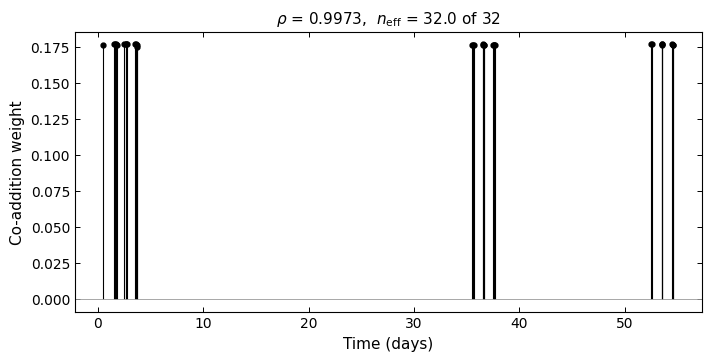

In [12]:
harps.build_tiravel_template(rv_library)
tir_h = harps.tiravel
print(f"rho = {tir_h.rho:.4f}; effective number of contributing epochs = "
      f"{tir_h.diagnostics['n_eff']:.1f} of {harps.sample_size}")

fig = tir_h.plot_weights(times=harps.time_list)
plt.show()

Near-equal weights: every epoch contributes, and none anti-correlates with the rest (a negative
weight would flag a bad spectrum or a wrong velocity). Do the two templates agree?

correlation of the TIRAVEL and library templates: 0.895


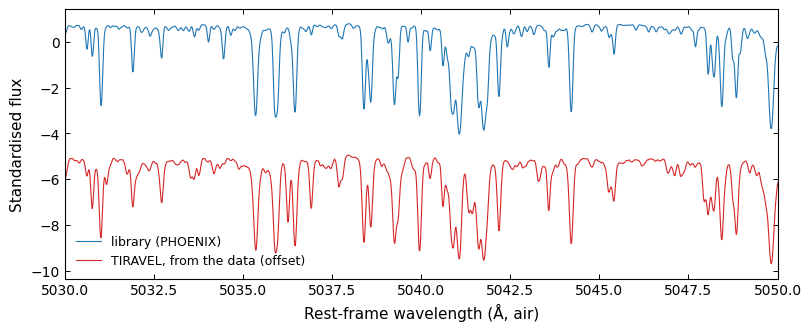

In [13]:
grid = np.linspace(5010, 5070, 6000)
lib_line = standardise(np.interp(grid, library.model.wv[0], library.model.sp[0]))
tir_line = standardise(np.interp(grid, tir_h.template.model.wv[0], tir_h.template.model.sp[0]))
print(f"correlation of the TIRAVEL and library templates: {np.corrcoef(lib_line, tir_line)[0, 1]:.3f}")

fig, ax = plt.subplots()
plot_extra(ax, grid, lib_line, lw=0.8, label="library (PHOENIX)")
plot_model(ax, grid, tir_line - 6, lw=0.8, label="TIRAVEL, from the data (offset)")
ax.set_xlim(5030, 5050)
ax.set_xlabel("Rest-frame wavelength (Å, air)")
ax.set_ylabel("Standardised flux")
ax.legend(loc="lower left")
plt.show()

The same lines, at the same positions. The correlation is lower than in the simulation, where
the reference was the exact noiseless spectrum; here it is only a model of the star. Finally,
the RVs against the TIRAVEL template:

TIRAVEL - library RVs: mean +0.00 m/s, rms 2.2 m/s (the RV rms itself is 14.1 m/s)


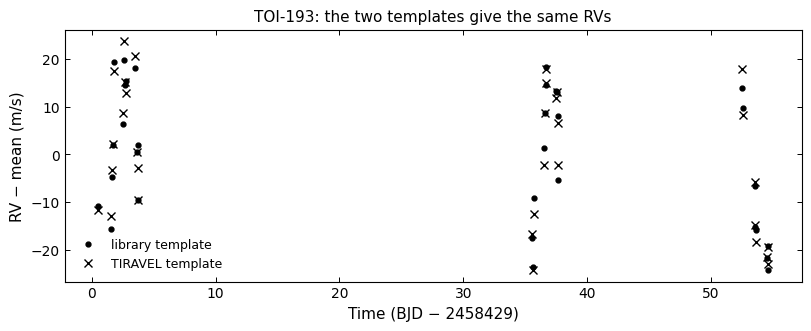

In [14]:
harps.calc_rv_against_template(tir_h.template, dv=0.1, vel_bound=150)
rv_tiravel = harps.vels.copy()
diff = rv_tiravel - rv_library
print(f"TIRAVEL - library RVs: mean {diff.mean() * 1e3:+.2f} m/s, rms {diff.std() * 1e3:.1f} m/s "
      f"(the RV rms itself is {rv_library.std() * 1e3:.1f} m/s)")

by_time = np.argsort(harps.time_list)
t = np.asarray(harps.time_list)[by_time]
fig, ax = plt.subplots()
plot_points(ax, t, (rv_library - rv_library.mean())[by_time] * 1e3, label="library template")
plot_points(ax, t, (rv_tiravel - rv_tiravel.mean())[by_time] * 1e3, fmt="x", ms=6,
            label="TIRAVEL template")
ax.set_xlabel(f"Time (BJD − {harps.first_time})")
ax.set_ylabel("RV − mean (m/s)")
ax.set_title("TOI-193: the two templates give the same RVs")
ax.legend()
plt.show()

The mean difference is ~0 because the TIRAVEL template inherits the zero point of the library
velocities it was built from.

## Summary / next

- TIRAVEL shifts the epochs to rest and co-adds them with eigenvector weights:
  `Observations.build_tiravel_template(velocities)` gives `obs.tiravel` and `obs.tiravel_template`.
- ρ measures how well the trial velocities align the spectra, diluted by the noise
  ($1 - \rho \propto (S/N)^{-2}$); with noise it still peaks at the true velocities.
- The template averages the noise down by about $\sqrt{n_\mathrm{eff}}$ (5.4 for 30 epochs at S/N 50).
- Only velocity differences matter: the template inherits the input zero point.
- On simulated data and on HARPS TOI-193, the data-built template reproduces the reference
  template and its RVs.

**Next:** `05_finding_periods.ipynb`: periodograms of RVs and of spectra.